# 02 · Stream profile — primary city of Student A (Guimarães)

**PA04 · T4 Humid vs Dry Regime · Textile Storage Facility**

**Requirement (Ch. 4, 9):** each student characterises the stream of their primary city *before modelling*.
Both city notebooks (02 Guimarães, 03 Viana do Castelo) are **the same template**: only `CITY_KEY` changes. That way the two cities get the same analytical logic, as the report requires (sections 3 and 4).

This notebook only **reads** the outputs of `01_data_and_target.ipynb`. τ_H is read from the frozen configuration and is never recomputed.

| Step | Content | Ch. 9 item |
|---|---|---|
| 1 | Load the processed stream and the frozen τ_H | — |
| 2 | Data quality, missing and invalid observations | 1 |
| 3 | Descriptive statistics (overall, by phase, by season) | 2 |
| 4 | Temporal evolution of the variables | 3 |
| 5 | Target frequency and class distribution | 4 |
| 6 | Rolling / window behaviour | 5 |
| 7 | Unusual and extreme observations | 6 |
| 8 | **Original analysis 1:** persistence of humid and dry regimes | Ch. 3.2 |
| 9 | **Original analysis 2:** hour-of-day × month profile of the humid regime | Ch. 3.2 |
| 10 | **Original analysis 3:** regime transitions and the persistence reference | Ch. 3.2 |
| 11 | Business interpretation | 7 |
| 12 | Save tables and figures | Ch. 15.2 |

All statistics here are **descriptive** and cover the full period. Nothing in this notebook is fitted or fed into a model. Fitting uses the warm-up only (notebook 01 / 04).

> **AI policy (Ch. 16):** cells marked *📝 For the report* are for your own interpretation. Write them yourself.

## 1. Load the processed stream and the frozen threshold

In [1]:
CITY_KEY = "guimaraes"                   # the only lines that differ between 02 and 03
NB_CODE = "02"

In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

from utils import ROOT, load_config

config = load_config()
storage_cfg = config["storage"]
RESULTS_DIR = ROOT / storage_cfg["results_dir"]
FIGURES_DIR = ROOT / storage_cfg["figures_dir"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

frozen = json.loads((RESULTS_DIR / "config_part1.json").read_text(encoding="utf-8"))
TAU_H = frozen["tau_H"]                                 # read, never recompute
TARGET_SOURCE = frozen["target_source"]
VARIABLES = frozen["hourly_variables"]
CITY = frozen["cities"][CITY_KEY]
LOCAL_TZ = config["data"]["timezone"]                   # Europe/Lisbon (with DST)

df = pd.read_csv(ROOT / frozen["processed_files"][CITY_KEY], parse_dates=["timestamp", "timestamp_utc"])
# True local clock (with summer time), used only for the hour-of-day / month views
df["local_time"] = df["timestamp_utc"].dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ)
df["hour"] = df["local_time"].dt.hour
df["month"] = df["local_time"].dt.month
df["year"] = df["timestamp"].dt.year
SEASON_OF_MONTH = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                   6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASONS = ["DJF", "MAM", "JJA", "SON"]
df["season"] = pd.Categorical(df["month"].map(SEASON_OF_MONTH), categories=SEASONS, ordered=True)

UNITS = {"temperature_2m": "°C", "relative_humidity_2m": "%", "precipitation": "mm", "wind_speed_10m": "km/h"}
LABELS = {"temperature_2m": "Temperature", "relative_humidity_2m": "Relative humidity",
          "precipitation": "Precipitation", "wind_speed_10m": "Wind speed"}
FIG = lambda name: FIGURES_DIR / f"{NB_CODE}_{CITY_KEY}_{name}.png"

print(f"{CITY['role']}: {CITY['name']}  |  rows = {len(df)}  |  "
      f"{df['timestamp'].min()} -> {df['timestamp'].max()}  |  tau_H = {TAU_H:.2f} %")

City A: Guimaraes  |  rows = 26304  |  2023-01-01 00:00:00 -> 2025-12-31 23:00:00  |  tau_H = 82.00 %


In [3]:
# Plot style for report figures: thin marks, recessive grid, one hue per role
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
HUMID, DRY = BLUE, ORANGE                                  # fixed meaning in every figure
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "lines.linewidth": 1.2, "legend.frameon": False, "font.size": 9.5,
})

## 2. Data quality — missing and invalid observations (Ch. 9 item 1)

Notebook 01 already checked chronology and definitional ranges. Here we add checks that can reveal **corrupted** data hidden among valid values:
* **constant runs:** a sensor or model "stuck" on the same value for many hours;
* **saturation:** RH = 100 %, which is physically valid (fog, rain) but worth counting;
* **calm hours:** wind = 0 km/h.

Rule (shared with the other city): **extreme ≠ erroneous.** Nothing is removed. Anything unusual is counted and documented.

In [4]:
def longest_constant_run(s: pd.Series) -> int:
    run_id = (s != s.shift()).cumsum()
    return int(s.groupby(run_id).size().max())


quality = pd.DataFrame({
    LABELS[v]: {
        "missing": int(df[v].isna().sum()),
        "flagged invalid (nb 01)": int(((df["quality_flag"] == "invalid") & df[v].notna()).sum()),
        "longest constant run (h)": longest_constant_run(df[v]),
        "distinct values": int(df[v].nunique()),
    }
    for v in VARIABLES
}).T
quality["unit"] = [UNITS[v] for v in VARIABLES]
quality

,missing,flagged invalid (nb 01),longest constant run (h),distinct values,unit
Temperature,0,0,5,391,°C
Relative humidity,0,0,14,87,%
Precipitation,0,0,540,101,mm
Wind speed,0,0,5,371,km/h


In [5]:
special = pd.Series({
    "RH = 100 % (saturation), hours": int((df[TARGET_SOURCE] == 100).sum()),
    "RH = 100 %, share": round((df[TARGET_SOURCE] == 100).mean(), 4),
    "wind = 0 km/h (calm), hours": int((df["wind_speed_10m"] == 0).sum()),
    "precipitation > 0 mm, hours": int((df["precipitation"] > 0).sum()),
    "precipitation > 0 mm, share": round((df["precipitation"] > 0).mean(), 4),
}, name=CITY["name"])
special.to_frame()

,Guimaraes
"RH = 100 % (saturation), hours",496.0000
"RH = 100 %, share",0.0189
"wind = 0 km/h (calm), hours",11.0000
"precipitation > 0 mm, hours",6036.0000
"precipitation > 0 mm, share",0.2295


Long constant runs are expected for **precipitation** (dry spells are runs of 0 mm). For temperature or humidity a very long run would be suspicious.

> 📝 **For the report:** is there any evidence of invalid data? State what was checked and the decision (keep / flag / correct).

## 3. Descriptive statistics (Ch. 9 item 2)

In [6]:
desc = df[VARIABLES].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["skew"] = df[VARIABLES].skew()
desc.index = [f"{LABELS[v]} ({UNITS[v]})" for v in desc.index]
desc.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
Temperature (°C),26304.0,15.60,6.56,-1.5,2.6,5.4,11.1,15.1,19.5,27.5,32.9,39.8,0.41
Relative humidity (%),26304.0,76.95,18.28,13.0,30.0,42.0,64.0,82.0,93.0,98.0,100.0,100.0,-0.76
Precipitation (mm),26304.0,0.21,0.77,0.0,0.0,0.0,0.0,0.0,0.0,1.2,3.9,17.7,6.63
Wind speed (km/h),26304.0,9.69,5.94,0.0,0.8,2.2,5.2,8.6,13.0,20.9,27.5,44.0,1.01


In [7]:
# By phase: is the evaluation stream (2024-2025) distributed like the warm-up (2023)?
by_phase = df.groupby("phase", sort=False)[VARIABLES].agg(["mean", "std", "median"]).T
by_phase.index = by_phase.index.set_levels([LABELS[v] for v in by_phase.index.levels[0]], level=0)
by_phase.round(2)

phase                     warm-up  evaluation
Temperature       mean      15.49       15.66
                  std        6.38        6.64
                  median    15.40       14.90
Relative humidity mean      77.65       76.60
                  std       17.60       18.60
                  median    82.00       81.00
Precipitation     mean       0.21        0.20
                  std        0.82        0.74
                  median     0.00        0.00
Wind speed        mean      10.03        9.52
                  std        5.95        5.94
                  median     8.90        8.50

In [8]:
# By season (DJF = winter, MAM = spring, JJA = summer, SON = autumn)
by_season = df.groupby("season", observed=True)[VARIABLES].mean().rename(columns=LABELS)
by_season["humid share (y=1)"] = df.groupby("season", observed=True)["y"].mean()
by_season.round(2)

,Temperature,Relative humidity,Precipitation,Wind speed,humid share (y=1)
season,,,,,
DJF,9.75,81.82,0.27,10.42,0.59
MAM,14.12,76.48,0.21,10.30,0.48
JJA,22.04,70.32,0.05,8.08,0.37
SON,16.40,79.30,0.30,9.98,0.56


## 4. Temporal evolution (Ch. 9 item 3)

Daily aggregates make three years of hourly data readable: daily means (daily **total** for precipitation).
One panel per variable, because the variables have different units (no dual axis).

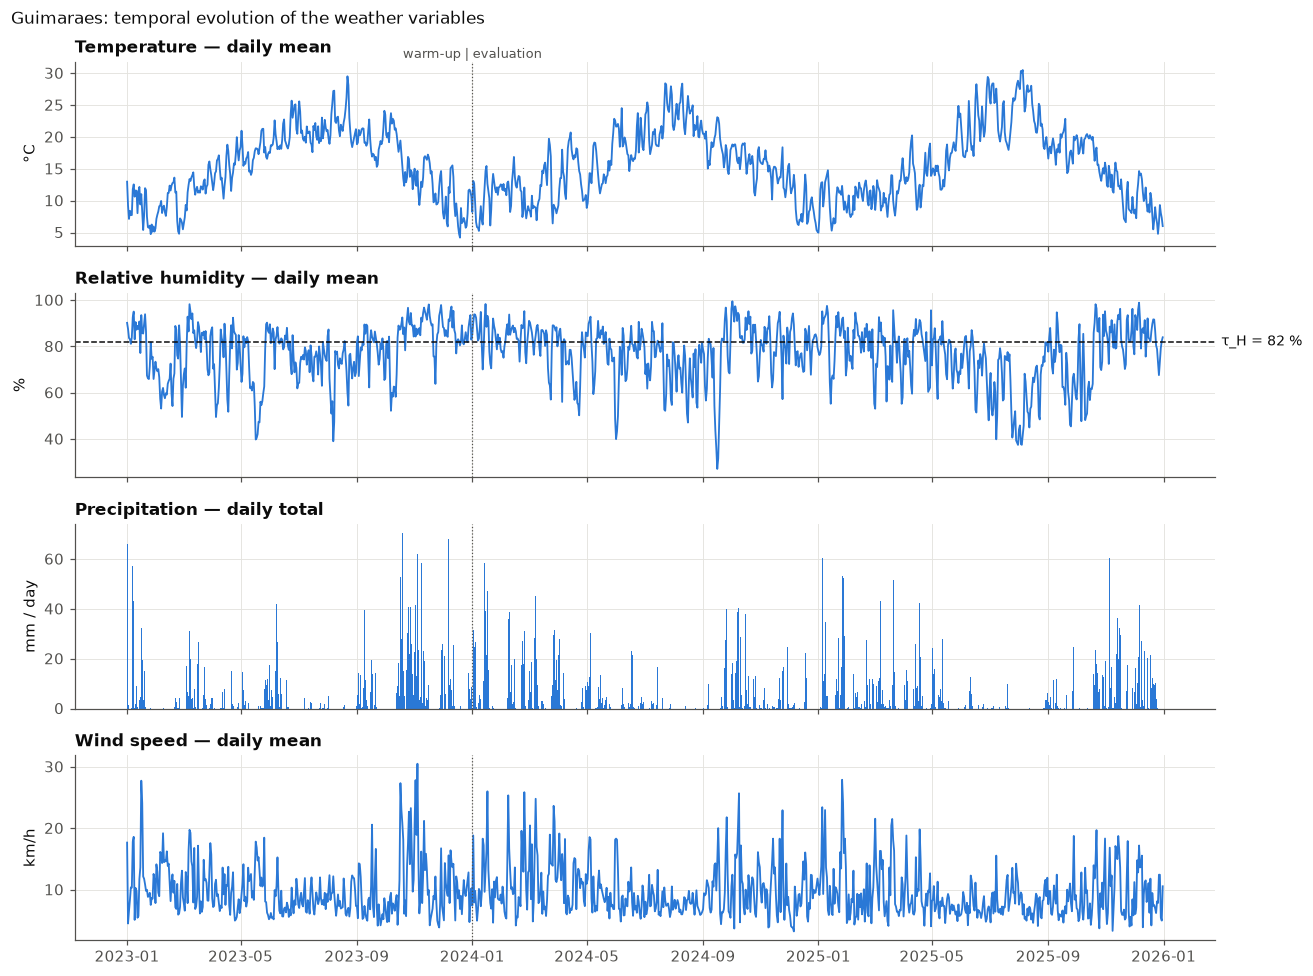

In [9]:
daily = df.set_index("timestamp")[VARIABLES].resample("D").agg(
    {"temperature_2m": "mean", "relative_humidity_2m": "mean", "precipitation": "sum", "wind_speed_10m": "mean"})

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, v in zip(axes, VARIABLES):
    if v == "precipitation":
        ax.bar(daily.index, daily[v], width=1.0, color=BLUE, linewidth=0)
        ax.set_ylabel("mm / day")
    else:
        ax.plot(daily.index, daily[v], color=BLUE)
        ax.set_ylabel(UNITS[v])
    if v == TARGET_SOURCE:
        ax.axhline(TAU_H, color=INK, linestyle="--", linewidth=1)
        ax.annotate(f"τ_H = {TAU_H:.0f} %", xy=(1.0, TAU_H), xycoords=("axes fraction", "data"),
                    xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
    ax.set_title(f"{LABELS[v]} — daily {'total' if v == 'precipitation' else 'mean'}", loc="left")
    ax.axvline(pd.Timestamp(frozen["evaluation_start"]), color=INK_2, linewidth=0.8, linestyle=":")
axes[0].annotate("warm-up | evaluation", xy=(pd.Timestamp(frozen["evaluation_start"]), 1.02),
                 xycoords=("data", "axes fraction"), ha="center", color=INK_2, fontsize=8.5)
fig.suptitle(f"{CITY['name']}: temporal evolution of the weather variables", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG("01_daily_evolution"))
plt.show()

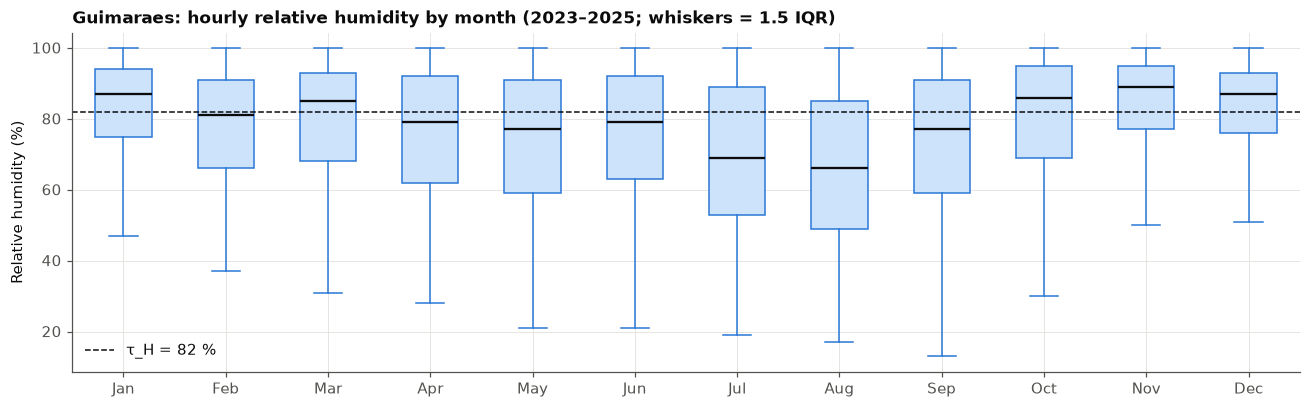

In [10]:
# Seasonal cycle of the target-defining variable: hourly RH by calendar month (all years)
fig, ax = plt.subplots(figsize=(12, 3.8))
data_by_month = [df.loc[df["month"] == m, TARGET_SOURCE].values for m in range(1, 13)]
ax.boxplot(data_by_month, widths=0.55, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=INK, linewidth=1.5),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.axhline(TAU_H, color=INK, linestyle="--", linewidth=1, label=f"τ_H = {TAU_H:.0f} %")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Relative humidity (%)")
ax.set_title(f"{CITY['name']}: hourly relative humidity by month (2023–2025; whiskers = 1.5 IQR)", loc="left")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG("02_rh_by_month"))
plt.show()

> 📝 **For the report:** describe the seasonal cycle and any differences between the years.

## 5. Target frequency and class distribution (Ch. 9 item 4)

Target T4: y = 1 (humid) if RH_t ≥ τ_H. The threshold τ_H is the same for both cities, so these shares are directly comparable with the other city.

In [11]:
def class_table(group_col):
    g = df.groupby(group_col, observed=True, sort=False)["y"]
    t = g.agg(hours="count", humid_hours="sum", humid_share="mean")
    t["dry_share"] = 1 - t["humid_share"]
    return t


class_by_phase = class_table("phase")
class_by_year = class_table("year")
class_by_season = class_table("season")
display(class_by_phase.round(3))
display(class_by_year.round(3))
display(class_by_season.round(3))

,hours,humid_hours,humid_share,dry_share
phase,,,,
warm-up,8760,4475.0,0.511,0.489
evaluation,17544,8683.0,0.495,0.505


,hours,humid_hours,humid_share,dry_share
year,,,,
2023,8760,4475.0,0.511,0.489
2024,8784,4560.0,0.519,0.481
2025,8760,4123.0,0.471,0.529


,hours,humid_hours,humid_share,dry_share
season,,,,
DJF,6504,3863.0,0.594,0.406
MAM,6621,3195.0,0.483,0.517
JJA,6624,2428.0,0.367,0.633
SON,6555,3672.0,0.560,0.440


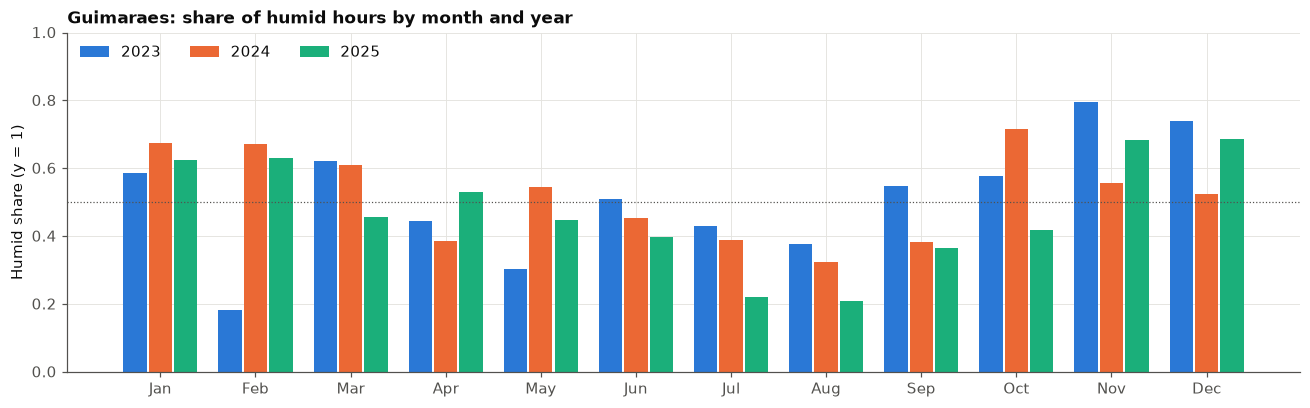

In [12]:
# Humid share per calendar month, one bar group per year (are the years alike?)
share_month_year = df.pivot_table(index="month", columns="year", values="y", aggfunc="mean")
years = list(share_month_year.columns)
colors = [BLUE, ORANGE, AQUA][: len(years)]
w = 0.8 / len(years)

fig, ax = plt.subplots(figsize=(12, 3.8))
for i, (yr, c) in enumerate(zip(years, colors)):
    ax.bar(share_month_year.index + (i - (len(years) - 1) / 2) * w, share_month_year[yr], width=w * 0.92,
           color=c, label=str(yr), linewidth=0)
ax.axhline(0.5, color=INK_2, linewidth=0.8, linestyle=":")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylim(0, 1)
ax.set_ylabel("Humid share (y = 1)")
ax.set_title(f"{CITY['name']}: share of humid hours by month and year", loc="left")
ax.legend(ncol=len(years), loc="upper left")
fig.tight_layout()
fig.savefig(FIG("03_humid_share_month_year"))
plt.show()

> 📝 **For the report:** how balanced are the classes in the evaluation stream, and how stable is the humid share across years and seasons?

## 6. Rolling / window behaviour (Ch. 9 item 5)

Trailing windows at the two scales the handbook recommends (Ch. 8.2), plus one week for the regime scale:
* **6 h / 24 h rolling mean and std of RH:** short-term level and volatility;
* **7-day (168 h) rolling humid share:** how the regime drifts over time.

These windows are descriptive and end at *t*. In notebook 04 the feature windows end at **t−1**, so they cannot leak the label.

In [13]:
rh = df.set_index("timestamp")[TARGET_SOURCE]
y = df.set_index("timestamp")["y"]
rolling = pd.DataFrame({
    "rh_mean_6h": rh.rolling(6, min_periods=6).mean(),
    "rh_std_6h": rh.rolling(6, min_periods=6).std(),
    "rh_mean_24h": rh.rolling(24, min_periods=24).mean(),
    "rh_std_24h": rh.rolling(24, min_periods=24).std(),
    "humid_share_7d": y.rolling(168, min_periods=168).mean(),
})
rolling_summary = rolling.describe(percentiles=[0.05, 0.5, 0.95]).T
rolling_summary.round(2)

,count,mean,std,min,5%,50%,95%,max
rh_mean_6h,26299.0,76.95,17.05,15.33,44.17,80.83,97.50,100.00
rh_std_6h,26299.0,5.93,4.12,0.00,0.89,5.04,13.67,23.74
rh_mean_24h,26281.0,76.94,12.60,25.04,52.38,79.54,93.75,99.67
rh_std_24h,26281.0,12.60,4.94,0.56,4.04,12.76,20.40,28.64
humid_share_7d,26137.0,0.50,0.21,0.00,0.10,0.51,0.82,0.98


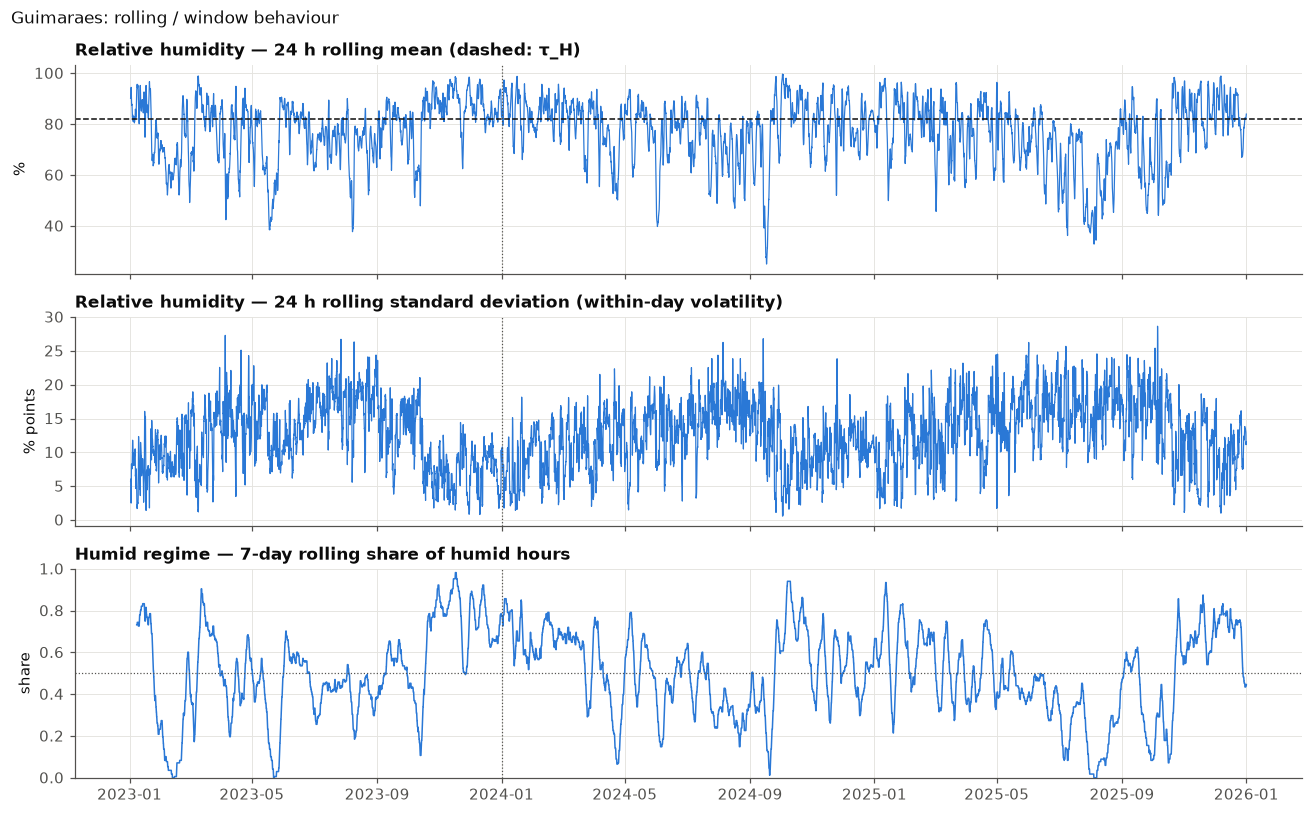

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)

axes[0].plot(rolling.index, rolling["rh_mean_24h"], color=BLUE, linewidth=0.8)
axes[0].axhline(TAU_H, color=INK, linestyle="--", linewidth=1)
axes[0].set_ylabel("%")
axes[0].set_title("Relative humidity — 24 h rolling mean (dashed: τ_H)", loc="left")

axes[1].plot(rolling.index, rolling["rh_std_24h"], color=BLUE, linewidth=0.8)
axes[1].set_ylabel("% points")
axes[1].set_title("Relative humidity — 24 h rolling standard deviation (within-day volatility)", loc="left")

axes[2].plot(rolling.index, rolling["humid_share_7d"], color=BLUE, linewidth=1)
axes[2].axhline(0.5, color=INK_2, linewidth=0.8, linestyle=":")
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("share")
axes[2].set_title("Humid regime — 7-day rolling share of humid hours", loc="left")

for ax in axes:
    ax.axvline(pd.Timestamp(frozen["evaluation_start"]), color=INK_2, linewidth=0.8, linestyle=":")
fig.suptitle(f"{CITY['name']}: rolling / window behaviour", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG("04_rolling_windows"))
plt.show()

**6 h vs 24 h window, zoomed in.** Over three years the 6 h curves are too dense to read, so the two window sizes are compared on a two-week excerpt.
The 6 h window follows short changes within the day. The 24 h window always spans one full day–night cycle, so it smooths the daily cycle away. Change `ZOOM_START` to look at another period.

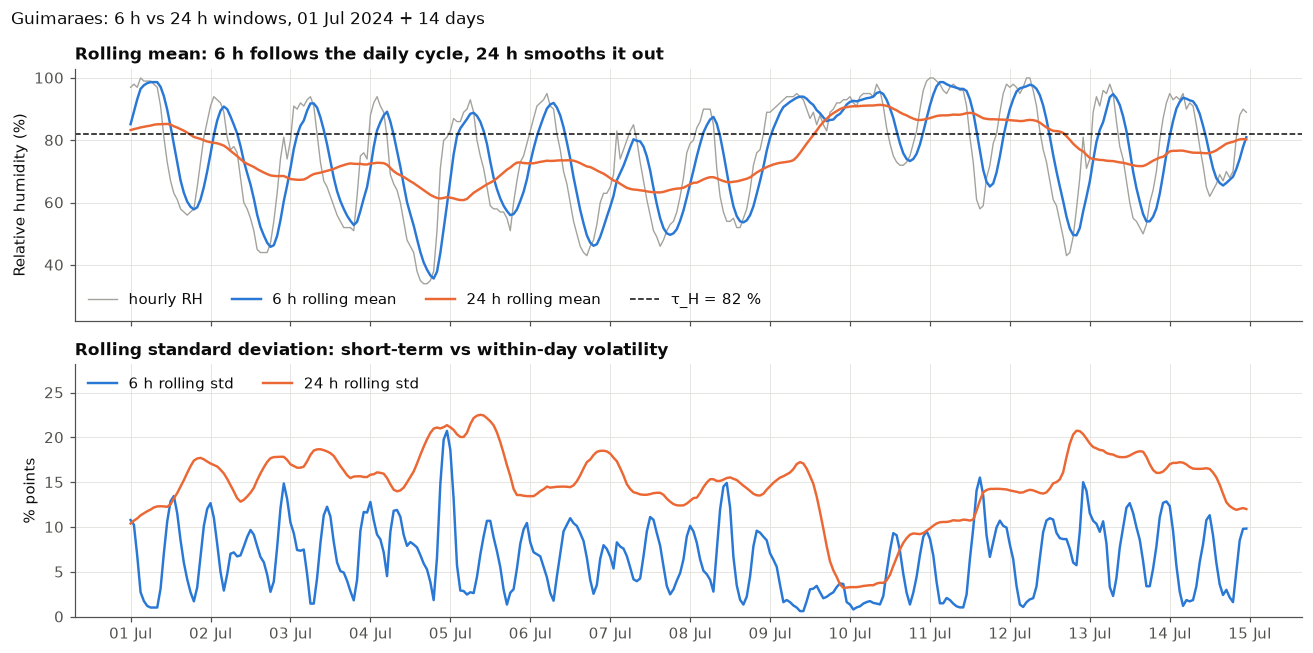

In [15]:
import matplotlib.dates as mdates

ZOOM_START, ZOOM_DAYS = pd.Timestamp("2024-07-01"), 14     # summer: strongest daily cycle (see step 9)
zoom = slice(ZOOM_START, ZOOM_START + pd.Timedelta(days=ZOOM_DAYS) - pd.Timedelta(hours=1))
GREY = "#a3a29c"

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax = axes[0]
ax.plot(rh[zoom].index, rh[zoom], color=GREY, linewidth=0.9, label="hourly RH")
ax.plot(rolling.loc[zoom, "rh_mean_6h"].index, rolling.loc[zoom, "rh_mean_6h"], color=BLUE, linewidth=1.6,
        label="6 h rolling mean")
ax.plot(rolling.loc[zoom, "rh_mean_24h"].index, rolling.loc[zoom, "rh_mean_24h"], color=ORANGE, linewidth=1.6,
        label="24 h rolling mean")
ax.axhline(TAU_H, color=INK, linestyle="--", linewidth=1, label=f"τ_H = {TAU_H:.0f} %")
ax.set_ylim(rh[zoom].min() - 12, 103)                     # room for the legend below the curves
ax.set_ylabel("Relative humidity (%)")
ax.set_title("Rolling mean: 6 h follows the daily cycle, 24 h smooths it out", loc="left")
ax.legend(ncol=4, loc="lower left")

ax = axes[1]
ax.plot(rolling.loc[zoom, "rh_std_6h"].index, rolling.loc[zoom, "rh_std_6h"], color=BLUE, linewidth=1.6,
        label="6 h rolling std")
ax.plot(rolling.loc[zoom, "rh_std_24h"].index, rolling.loc[zoom, "rh_std_24h"], color=ORANGE, linewidth=1.6,
        label="24 h rolling std")
ax.set_ylim(0, rolling.loc[zoom, ["rh_std_6h", "rh_std_24h"]].max().max() * 1.25)
ax.set_ylabel("% points")
ax.set_title("Rolling standard deviation: short-term vs within-day volatility", loc="left")
ax.legend(ncol=2, loc="upper left")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

fig.suptitle(f"{CITY['name']}: 6 h vs 24 h windows, {ZOOM_START:%d %b %Y} + {ZOOM_DAYS} days",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG("04b_rolling_6h_vs_24h"))
plt.show()

In [16]:
# How much does the 24 h volatility of RH depend on the season?
rolling_season = rolling.assign(season=df.set_index("timestamp")["season"]).groupby("season", observed=True)[
    ["rh_std_6h", "rh_std_24h", "humid_share_7d"]].median()
rolling_season.round(2)

,rh_std_6h,rh_std_24h,humid_share_7d
season,,,
DJF,3.76,9.62,0.65
MAM,5.39,13.67,0.48
JJA,6.66,16.21,0.38
SON,4.38,11.56,0.57


> 📝 **For the report:** what do the windows show about stability or volatility of the humidity regime? Which window scale looks more informative for the features of Representation B?

## 7. Unusual and extreme observations (Ch. 9 item 6)

**Extreme ≠ erroneous.** Extremes are listed and counted, never removed.
* Tail counts beyond the 1st / 99th percentile and beyond 1.5 × IQR (a description, not a removal rule);
* the most extreme hours per variable, with timestamps, so they can be checked against known weather episodes.

In [17]:
def tail_counts(s: pd.Series) -> dict:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    p01, p99 = s.quantile([0.01, 0.99])
    return {
        "P1": p01, "P99": p99,
        "hours < P1": int((s < p01).sum()), "hours > P99": int((s > p99).sum()),
        "hours outside 1.5 IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        "min": s.min(), "max": s.max(),
    }


extremes = pd.DataFrame({LABELS[v]: tail_counts(df[v]) for v in VARIABLES}).T
extremes.round(2)

,P1,P99,hours < P1,hours > P99,hours outside 1.5 IQR,min,max
Temperature,2.6,32.9,258.0,258.0,347.0,-1.5,39.8
Relative humidity,30.0,100.0,259.0,0.0,27.0,13.0,100.0
Precipitation,0.0,3.9,0.0,263.0,6036.0,0.0,17.7
Wind speed,0.8,27.5,217.0,261.0,525.0,0.0,44.0


In [18]:
# Most extreme hours (top 5 high; bottom 5 low for temperature and RH)
rows = []
for v in VARIABLES:
    for kind, part in [("highest", df.nlargest(5, v)), ("lowest", df.nsmallest(5, v))]:
        if kind == "lowest" and v in ("precipitation", "wind_speed_10m"):
            continue                                 # minima are just 0 for these
        for _, r in part.iterrows():
            rows.append({"variable": LABELS[v], "kind": kind, "timestamp": r["timestamp"], "value": r[v],
                         "RH at that hour": r[TARGET_SOURCE], "y": r["y"]})
top_extremes = pd.DataFrame(rows)
top_extremes

,variable,kind,timestamp,value,RH at that hour,y
0,Temperature,highest,2025-08-05 15:00:00,39.8,17,0.0
1,Temperature,highest,2025-08-05 16:00:00,39.5,18,0.0
2,Temperature,highest,2025-08-05 14:00:00,39.3,17,0.0
3,Temperature,highest,2023-08-22 15:00:00,39.2,26,0.0
4,Temperature,highest,2025-08-05 17:00:00,38.8,20,0.0
5,Temperature,lowest,2023-12-19 08:00:00,-1.5,88,1.0
6,Temperature,lowest,2023-12-19 09:00:00,-1.5,88,1.0
7,Temperature,lowest,2023-12-19 07:00:00,-1.4,89,1.0
8,Temperature,lowest,2023-12-19 06:00:00,-1.1,89,1.0
9,Temperature,lowest,2023-12-19 05:00:00,-0.8,89,1.0


In [19]:
# Daily extremes: the days with the heaviest rain and the lowest daily mean humidity
extreme_days = pd.concat({
    "wettest days (mm)": daily["precipitation"].nlargest(5),
    "driest days (mean RH %)": daily["relative_humidity_2m"].nsmallest(5),
    "most humid days (mean RH %)": daily["relative_humidity_2m"].nlargest(5),
}).round(1).rename("value").to_frame()
extreme_days

value
                            timestamp        
wettest days (mm)           2023-10-19   70.5
                            2023-12-07   67.9
                            2023-01-01   66.1
                            2023-11-04   61.9
                            2025-11-05   60.6
driest days (mean RH %)     2024-09-16   27.1
                            2024-09-17   31.5
                            2024-09-15   36.0
                            2025-07-31   37.5
                            2025-08-04   37.5
most humid days (mean RH %) 2024-10-02   99.5
                            2025-12-06   98.9
                            2024-01-15   98.3
                            2023-03-08   98.2
                            2025-10-21   98.2

> 📝 **For the report:** are the extremes plausible weather (storms, dry wind episodes, fog)? Are they relevant to textile storage, e.g. long saturated periods versus short dry spikes?

## 8. Original analysis 1 — persistence of humid and dry regimes (Ch. 3.2)

**Why it matters for textile storage:** a single humid hour is harmless, but a humid regime that **persists for days** is what drives moisture uptake, mould risk and dehumidification demand.
An **episode** is a maximal run of consecutive hours with the same label. Episodes at the very start and end of the period are cut by the period boundary.

In [20]:
runs_src = df[["timestamp", "y"]].dropna()
run_id = (runs_src["y"] != runs_src["y"].shift()).cumsum()
episodes = runs_src.groupby(run_id).agg(state=("y", "first"), start=("timestamp", "first"),
                                        end=("timestamp", "last"), hours=("y", "size"))
episodes["regime"] = np.where(episodes["state"] == 1, "humid", "dry")
episodes["phase"] = np.where(episodes["start"] <= pd.Timestamp(frozen["warmup_end"]), "warm-up", "evaluation")


def episode_stats(e: pd.DataFrame) -> pd.Series:
    h = e["hours"]
    return pd.Series({
        "episodes": len(h), "mean (h)": h.mean(), "median (h)": h.median(), "P90 (h)": h.quantile(0.9),
        "max (h)": h.max(), "episodes ≥ 24 h": int((h >= 24).sum()), "episodes ≥ 72 h": int((h >= 72).sum()),
        "share of regime hours in episodes ≥ 24 h": h[h >= 24].sum() / h.sum(),
    })


persistence = pd.DataFrame({regime: episode_stats(g) for regime, g in episodes.groupby("regime")})
persistence.round(2)

,dry,humid
episodes,1052.00,1053.00
mean (h),12.50,12.50
median (h),10.00,12.00
P90 (h),20.00,20.00
max (h),235.00,119.00
episodes ≥ 24 h,75.00,68.00
episodes ≥ 72 h,11.00,5.00
share of regime hours in episodes ≥ 24 h,0.33,0.25


In [21]:
# Persistence by season (humid episodes only), by the season in which the episode starts
humid_eps = episodes[episodes["regime"] == "humid"].copy()
humid_eps["season"] = pd.Categorical(humid_eps["start"].dt.month.map(SEASON_OF_MONTH), categories=SEASONS, ordered=True)
humid_eps.groupby("season", observed=True)["hours"].agg(
    episodes="count", mean_h="mean", median_h="median", max_h="max").round(1)

,episodes,mean_h,median_h,max_h
season,,,,
DJF,262,14.7,13.0,83
MAM,285,11.3,12.0,70
JJA,263,9.3,10.0,38
SON,243,15.1,14.0,119


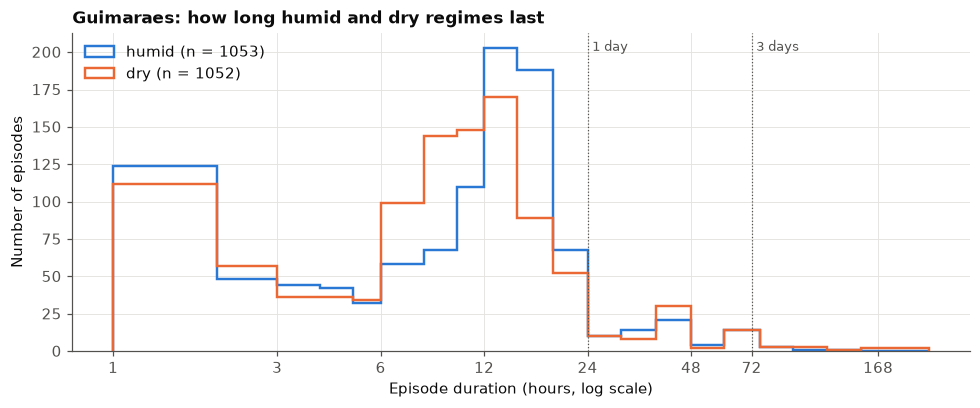

In [22]:
# Distribution of episode durations (log-spaced bins: most episodes are short, a few are very long)
max_h = int(episodes["hours"].max())
bins = np.unique(np.round(np.logspace(0, np.log10(max_h + 1), 25)).astype(int))

fig, ax = plt.subplots(figsize=(9, 3.8))
for regime, color in [("humid", HUMID), ("dry", DRY)]:
    h = episodes.loc[episodes["regime"] == regime, "hours"]
    ax.hist(h, bins=bins, histtype="step", linewidth=1.6, color=color, label=f"{regime} (n = {len(h)})")
ax.set_xscale("log")
ticks = [1, 3, 6, 12, 24, 48, 72, 168]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Episode duration (hours, log scale)")
ax.set_ylabel("Number of episodes")
for x, lab in [(24, "1 day"), (72, "3 days")]:
    ax.axvline(x, color=INK_2, linewidth=0.8, linestyle=":")
    ax.annotate(lab, xy=(x, 1), xycoords=("data", "axes fraction"), xytext=(3, -12),
                textcoords="offset points", color=INK_2, fontsize=8.5)
ax.set_title(f"{CITY['name']}: how long humid and dry regimes last", loc="left")
ax.legend()
fig.tight_layout()
fig.savefig(FIG("05_episode_durations"))
plt.show()

In [23]:
# The longest humid episodes (dates for the report / cross-check with weather history)
episodes[episodes["regime"] == "humid"].nlargest(5, "hours")[["start", "end", "hours", "phase"]].reset_index(drop=True)

,start,end,hours,phase
0,2025-11-12 13:00:00,2025-11-17 11:00:00,119,evaluation
1,2023-11-12 16:00:00,2023-11-17 12:00:00,117,warm-up
2,2023-11-26 18:00:00,2023-11-30 15:00:00,94,warm-up
3,2024-09-30 18:00:00,2024-10-04 11:00:00,90,evaluation
4,2023-12-28 00:00:00,2023-12-31 10:00:00,83,warm-up


> 📝 **For the report:** how persistent is the humid regime in this city? Long humid episodes are an operational risk for textile storage. Compare later with the other city in notebook 04.

## 9. Original analysis 2 — when is it humid? Hour-of-day × month profile (Ch. 3.2)

Share of humid hours for every (month, local hour) cell, in **local time with summer time** (`local_time`), because warehouse operations (ventilation, loading doors) follow the local clock.

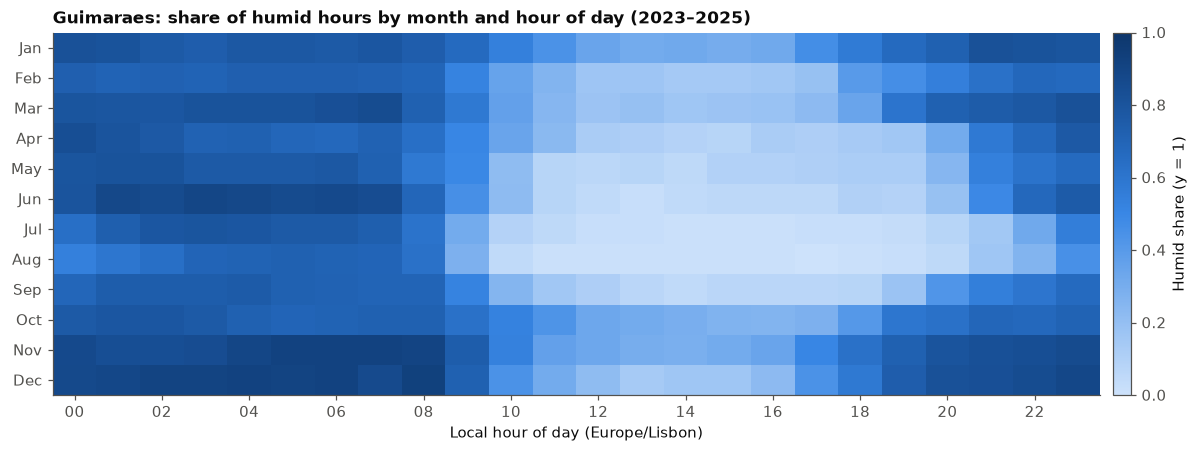

In [24]:
profile = df.pivot_table(index="month", columns="hour", values="y", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(profile.values, aspect="auto", cmap=SEQ, vmin=0, vmax=1, origin="upper")
ax.set_yticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("Local hour of day (Europe/Lisbon)")
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Humid share (y = 1)")
ax.set_title(f"{CITY['name']}: share of humid hours by month and hour of day (2023–2025)", loc="left")
fig.tight_layout()
fig.savefig(FIG("06_hour_month_heatmap"))
plt.show()

In [25]:
# Daily cycle summary: most / least humid local hour per season, and the day-night amplitude
hourly_by_season = df.pivot_table(index="season", columns="hour", values="y", aggfunc="mean", observed=True)
pd.DataFrame({
    "most humid hour": hourly_by_season.idxmax(axis=1),
    "max share": hourly_by_season.max(axis=1),
    "least humid hour": hourly_by_season.idxmin(axis=1),
    "min share": hourly_by_season.min(axis=1),
    "amplitude (max - min)": hourly_by_season.max(axis=1) - hourly_by_season.min(axis=1),
}).round(2)

,most humid hour,max share,least humid hour,min share,amplitude (max - min)
season,,,,,
DJF,0,0.81,15,0.20,0.61
MAM,0,0.81,14,0.10,0.71
JJA,3,0.79,13,0.02,0.78
SON,2,0.79,14,0.21,0.58


> 📝 **For the report:** is the humid regime driven mainly by the daily cycle (nights) or by the season? What could that mean for when the warehouse is ventilated?

## 10. Original analysis 3 — regime transitions and the persistence reference (Ch. 3.2)

How often does the regime switch from one hour to the next? The transition matrix P(y_t | y_{t−1}) measures how "sticky" the regime is.

A trivial **persistence rule** ŷ_t = y_{t−1} uses only past information, so it is leakage-free. It gives a **reference level** for notebook 04: an incremental model that cannot beat it has not learned more than "the regime stays the same".
Computed on the **evaluation stream only** (2024–2025), the same events the models will be scored on.

In [26]:
ev = df[df["phase"] == "evaluation"][["timestamp", "y"]].copy()
ev["y_prev"] = df["y"].shift(1).loc[ev.index]          # previous hour (the first one comes from the warm-up)
ev = ev.dropna()

transitions = pd.crosstab(ev["y_prev"].map({0: "dry (t-1)", 1: "humid (t-1)"}),
                          ev["y"].map({0: "dry (t)", 1: "humid (t)"}), normalize="index")
display(transitions.round(3))

switches_per_day = (ev["y"] != ev["y_prev"]).mean() * 24
print(f"Regime switches per day (average): {switches_per_day:.2f}")

y,dry (t),humid (t)
y_prev,,
dry (t-1),0.921,0.079
humid (t-1),0.080,0.920


Regime switches per day (average): 1.91


In [27]:
y_true, y_pred = ev["y"].astype(int), ev["y_prev"].astype(int)
persistence_reference = pd.Series({
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro-F1": f1_score(y_true, y_pred, average="macro"),
    "Precision (humid)": precision_score(y_true, y_pred, pos_label=1),
    "Recall (humid)": recall_score(y_true, y_pred, pos_label=1),
    "Majority-class accuracy": max(y_true.mean(), 1 - y_true.mean()),
}, name=f"persistence rule — {CITY['name']} (evaluation)")
persistence_reference.round(4).to_frame()

,persistence rule — Guimaraes (evaluation)
Accuracy,0.9204
Macro-F1,0.9204
Precision (humid),0.9196
Recall (humid),0.9196
Majority-class accuracy,0.5051


> 📝 **For the report / technical recommendation:** keep these numbers as the bar the models in notebook 04 have to clear.

## 11. Business interpretation (Ch. 9 item 7)

> 📝 **For the report — City A analysis.** Write this section yourself (AI policy, Ch. 16). Connect the evidence above to the business question, *How do humid and dry regimes differ between candidate warehouse locations?*, from the textile-storage perspective. For example:
> * how often the city is in the humid regime, and in which seasons and hours;
> * how long humid episodes last (persistence → environmental-control demand);
> * how volatile humidity is within a day (rolling std);
> * what the extremes and data quality imply;
> * what this evidence **cannot** say (one grid cell, three years, outdoor humidity only).

## 12. Save tables for the report and for notebook 04

In [28]:
key_numbers = pd.Series({
    "city": CITY["name"],
    "role": CITY["role"],
    "tau_H": TAU_H,
    "humid_share_all": df["y"].mean(),
    "humid_share_warmup": class_by_phase.loc["warm-up", "humid_share"],
    "humid_share_evaluation": class_by_phase.loc["evaluation", "humid_share"],
    **{f"humid_share_{s}": class_by_season.loc[s, "humid_share"] for s in SEASONS},
    "rh_mean": df[TARGET_SOURCE].mean(),
    "rh_std": df[TARGET_SOURCE].std(),
    "rh_std_24h_median": rolling["rh_std_24h"].median(),
    "rh_100_share": (df[TARGET_SOURCE] == 100).mean(),
    "humid_episode_mean_h": persistence.loc["mean (h)", "humid"],
    "humid_episode_max_h": persistence.loc["max (h)", "humid"],
    "humid_episodes_ge_24h": persistence.loc["episodes ≥ 24 h", "humid"],
    "humid_episodes_ge_72h": persistence.loc["episodes ≥ 72 h", "humid"],
    "dry_episode_mean_h": persistence.loc["mean (h)", "dry"],
    "switches_per_day_eval": switches_per_day,
    **{f"persistence_{k.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')}": v
       for k, v in persistence_reference.items()},
}, name="value")

out_dir = RESULTS_DIR / "profiles"
out_dir.mkdir(exist_ok=True)
key_numbers.to_frame().to_csv(out_dir / f"{NB_CODE}_{CITY_KEY}_key_numbers.csv")
episodes.to_csv(out_dir / f"{NB_CODE}_{CITY_KEY}_episodes.csv", index=False)
desc.to_csv(out_dir / f"{NB_CODE}_{CITY_KEY}_descriptive_stats.csv")
class_by_season.to_csv(out_dir / f"{NB_CODE}_{CITY_KEY}_class_by_season.csv")

print("Saved tables to", out_dir.relative_to(ROOT))
print("Saved figures:", *sorted(p.name for p in FIGURES_DIR.glob(f"{NB_CODE}_{CITY_KEY}_*.png")), sep="\n  ")
key_numbers.to_frame()

Saved tables to results/profiles
Saved figures:
  02_guimaraes_01_daily_evolution.png
  02_guimaraes_02_rh_by_month.png
  02_guimaraes_03_humid_share_month_year.png
  02_guimaraes_04_rolling_windows.png
  02_guimaraes_04b_rolling_6h_vs_24h.png
  02_guimaraes_05_episode_durations.png
  02_guimaraes_06_hour_month_heatmap.png


,value
city,Guimaraes
role,City A
tau_H,82.0
humid_share_all,0.500228
humid_share_warmup,0.510845
humid_share_evaluation,0.494927
humid_share_DJF,0.593942
humid_share_MAM,0.482556
humid_share_JJA,0.366546
humid_share_SON,0.560183
